In [1]:
from pathlib import Path
import polars as pl

print(f"Polars version: {pl.__version__}")

Polars version: 1.44.2


In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()

    for directory in [current, *current.parents]:
        if (directory / "pyproject.toml").exists():
            return directory

    raise FileNotFoundError(
        "Project root not found. Expected to find pyproject.toml.")

PROJECT_ROOT = find_project_root()
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data directory: {RAW_DATA_DIR}")

Project root: retail-demand-forecasting
Raw data directory: retail-demand-forecasting/data/raw


In [3]:
EXPECTED_FILES = {
    "train": "train.csv",
    "test": "test.csv",
    "stores": "stores.csv",
    "transactions": "transactions.csv",
    "oil": "oil.csv",
    "holidays": "holidays_events.csv",
}

file_paths = {
    name: RAW_DATA_DIR / filename
    for name, filename in EXPECTED_FILES.items()
}

missing_files = [
    str(path)
    for path in file_paths.values()
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required files:\n" + "\n".join(missing_files)
    )

print("All required raw files were found.")

All required raw files were found.


In [4]:
datasets = {
    name: pl.scan_csv(
        path,
        try_parse_dates=True,
        low_memory=True,)
    for name, path in file_paths.items()}

In [5]:
inventory = []

for name, lazy_frame in datasets.items():
    row_count = (
        lazy_frame
        .select(pl.len().alias("rows"))
        .collect()
        .item())

    schema = lazy_frame.collect_schema()

    inventory.append({
        "dataset": name,
        "rows": row_count,
        "columns": len(schema),
        "column_names": ", ".join(schema.names()),})

inventory_df = pl.DataFrame(inventory)
inventory_df

dataset,rows,columns,column_names
str,i64,i64,str
"""train""",3000888,6,"""id, date, store_nbr, family, s…"
"""test""",28512,5,"""id, date, store_nbr, family, o…"
"""stores""",54,5,"""store_nbr, city, state, type, …"
"""transactions""",83488,3,"""date, store_nbr, transactions"""
"""oil""",1218,2,"""date, dcoilwtico"""
"""holidays""",350,6,"""date, type, locale, locale_nam…"


In [6]:
for name, lazy_frame in datasets.items():
    print(f"\n{name.upper()}")
    print(lazy_frame.collect_schema())


TRAIN
Schema([('id', Int64), ('date', Date), ('store_nbr', Int64), ('family', String), ('sales', Float64), ('onpromotion', Int64)])

TEST
Schema([('id', Int64), ('date', Date), ('store_nbr', Int64), ('family', String), ('onpromotion', Int64)])

STORES
Schema([('store_nbr', Int64), ('city', String), ('state', String), ('type', String), ('cluster', Int64)])

TRANSACTIONS
Schema([('date', Date), ('store_nbr', Int64), ('transactions', Int64)])

OIL
Schema([('date', Date), ('dcoilwtico', Float64)])

HOLIDAYS
Schema([('date', Date), ('type', String), ('locale', String), ('locale_name', String), ('description', String), ('transferred', Boolean)])


In [7]:
null_summary = [] 

for name, lazy_frame in datasets.items():
    schema = lazy_frame.collect_schema()

    null_counts = (
        lazy_frame
        .select([
            pl.col(column).null_count().alias(column)
            for column in schema.names()
        ])
        .collect()
        .row(0, named=True)
    )

    for column, null_count in null_counts.items():
        if null_count > 0:
            null_summary.append({
                "dataset": name,
                "column": column,
                "null_count": null_count,
            })

null_summary_df = pl.DataFrame(
    null_summary,
    schema={
        "dataset": pl.String,
        "column": pl.String,
        "null_count": pl.Int64,
    },
)

null_summary_df

dataset,column,null_count
str,str,i64
"""oil""","""dcoilwtico""",43


In [8]:
date_summary = []

for name, lazy_frame in datasets.items():
    schema = lazy_frame.collect_schema()

    if "date" not in schema.names():
        continue

    result = (
        lazy_frame
        .select(
            pl.col("date").min().alias("min_date"),
            pl.col("date").max().alias("max_date"),
            pl.col("date").n_unique().alias("unique_dates"),
        )
        .collect()
        .row(0, named=True)
    )

    date_summary.append({
        "dataset": name,
        **result,
    })

date_summary_df = pl.DataFrame(date_summary)
date_summary_df

dataset,min_date,max_date,unique_dates
str,date,date,i64
"""train""",2013-01-01,2017-08-15,1684
"""test""",2017-08-16,2017-08-31,16
"""transactions""",2013-01-01,2017-08-15,1682
"""oil""",2013-01-01,2017-08-31,1218
"""holidays""",2012-03-02,2017-12-26,312


In [9]:
train_max_date = (
    datasets["train"]
    .select(pl.col("date").max())
    .collect()
    .item()
)

test_min_date = (
    datasets["test"]
    .select(pl.col("date").min())
    .collect()
    .item()
)

assert test_min_date > train_max_date
assert (test_min_date - train_max_date).days == 1

print("Train and test are chronologically separated without a gap.")

Train and test are chronologically separated without a gap.


In [10]:
primary_keys = {
    "train": ["id"],
    "test": ["id"],
    "stores": ["store_nbr"],
    "transactions": ["date", "store_nbr"],
    "oil": ["date"],}

In [11]:
def count_duplicate_keys(
    lazy_frame: pl.LazyFrame,
    keys: list[str],
) -> int:
    return (
        lazy_frame
        .group_by(keys)
        .len()
        .filter(pl.col("len") > 1)
        .select(pl.len().alias("duplicate_keys"))
        .collect()
        .item()
    )

In [12]:
duplicate_results = []

for name, keys in primary_keys.items():
    duplicate_results.append({
        "dataset": name,
        "key": ", ".join(keys),
        "duplicate_keys": count_duplicate_keys(
            datasets[name],
            keys,
        ),
    })

duplicate_results_df = pl.DataFrame(duplicate_results)
duplicate_results_df

dataset,key,duplicate_keys
str,str,i64
"""train""","""id""",0
"""test""","""id""",0
"""stores""","""store_nbr""",0
"""transactions""","""date, store_nbr""",0
"""oil""","""date""",0


In [13]:
train_business_duplicates = count_duplicate_keys(
    datasets["train"],
    ["date", "store_nbr", "family"],
)

test_business_duplicates = count_duplicate_keys(
    datasets["test"],
    ["date", "store_nbr", "family"],
)

print("Train business-key duplicates:", train_business_duplicates)
print("Test business-key duplicates:", test_business_duplicates)

Train business-key duplicates: 0
Test business-key duplicates: 0


In [14]:
sales_validation = (
    datasets["train"]
    .select(
        pl.col("sales").min().alias("min_sales"),
        pl.col("sales").max().alias("max_sales"),
        pl.col("sales").mean().alias("mean_sales"),
        (pl.col("sales") < 0).sum().alias("negative_sales"),
        (pl.col("sales") == 0).sum().alias("zero_sales"),
        pl.col("sales").n_unique().alias("unique_sales_values"),
    )
    .collect()
)

sales_validation

min_sales,max_sales,mean_sales,negative_sales,zero_sales,unique_sales_values
f64,f64,f64,u32,u32,u32
0.0,124717.0,357.775749,0,939130,379610


In [15]:
promotion_validation = []

for name in ["train", "test"]:
    result = (
        datasets[name]
        .select(
            pl.col("onpromotion").min().alias("minimum"),
            pl.col("onpromotion").max().alias("maximum"),
            (pl.col("onpromotion") < 0).sum().alias("negative_values"),
            (pl.col("onpromotion") > 0).sum().alias("rows_on_promotion"),
        )
        .collect()
        .row(0, named=True)
    )

    promotion_validation.append({
        "dataset": name,
        **result,
    })

pl.DataFrame(promotion_validation)

dataset,minimum,maximum,negative_values,rows_on_promotion
str,i64,i64,i64,i64
"""train""",0,741,0,611329
"""test""",0,646,0,12569


In [16]:
store_ids = (
    datasets["stores"]
    .select("store_nbr")
    .unique()
)

referential_integrity = []

for name in ["train", "test", "transactions"]:
    unknown_stores = (
        datasets[name]
        .select("store_nbr")
        .unique()
        .join(
            store_ids,
            on="store_nbr",
            how="anti",
        )
        .select(pl.len())
        .collect()
        .item()
    )

    referential_integrity.append({
        "dataset": name,
        "unknown_store_ids": unknown_stores,
    })

pl.DataFrame(referential_integrity)

dataset,unknown_store_ids
str,i64
"""train""",0
"""test""",0
"""transactions""",0


In [17]:
series_summary = []

for name in ["train", "test"]:
    result = (
        datasets[name]
        .select(
            pl.col("store_nbr").n_unique().alias("stores"),
            pl.col("family").n_unique().alias("families"),
            pl.col("date").n_unique().alias("dates"),
            pl.struct(["store_nbr", "family"])
            .n_unique()
            .alias("store_family_series"),
        )
        .collect()
        .row(0, named=True)
    )

    series_summary.append({
        "dataset": name,
        **result,
    })

series_summary_df = pl.DataFrame(series_summary)
series_summary_df

dataset,stores,families,dates,store_family_series
str,i64,i64,i64,i64
"""train""",54,33,1684,1782
"""test""",54,33,16,1782


## Initial data-quality findings

- Train and test contain 54 stores and 33 product families, producing 1,782 store-family time series.
- Primary and business keys contain no duplicates.
- All store identifiers are present in the store master table.
- Train and test are chronologically separated, and the test set represents a 16-day forecast horizon.
- The only explicit missing values are 43 observations in the oil-price variable.
- Approximately 31.3% of training observations have zero sales.
- Promotional activity is more frequent in the test period than in the training period, indicating a possible distribution shift.
- Transaction data does not cover every training date.
- Multiple holiday records can occur on the same date because events may have different geographical scopes.

In [18]:
train_dates = (
    datasets["train"]
    .select("date")
    .unique()
)

transaction_dates = (
    datasets["transactions"]
    .select("date")
    .unique()
)

missing_transaction_dates = (
    train_dates
    .join(
        transaction_dates,
        on="date",
        how="anti",
    )
    .sort("date")
    .collect())

missing_transaction_dates

date
date
2016-01-01
2016-01-03


In [19]:
transaction_store_coverage = (
    datasets["transactions"]
    .group_by("store_nbr")
    .agg(
        pl.col("date").min().alias("first_date"),
        pl.col("date").max().alias("last_date"),
        pl.col("date").n_unique().alias("observed_dates"),
        pl.col("transactions").min().alias("min_transactions"),
        pl.col("transactions").max().alias("max_transactions"),
        pl.col("transactions").mean().alias("mean_transactions"),
    )
    .sort("store_nbr")
    .collect())

transaction_store_coverage

store_nbr,first_date,last_date,observed_dates,min_transactions,max_transactions,mean_transactions
i64,date,date,u32,i64,i64,f64
1,2013-01-02,2017-08-15,1676,10,3023,1523.844272
2,2013-01-02,2017-08-15,1677,6,4060,1920.036374
3,2013-01-02,2017-08-15,1676,2213,6085,3201.879475
4,2013-01-02,2017-08-15,1676,785,3589,1502.98747
5,2013-01-02,2017-08-15,1677,721,3468,1400.045915
…,…,…,…,…,…,…
50,2013-01-02,2017-08-15,1677,1769,5456,2614.456768
51,2013-01-02,2017-08-15,1677,989,3572,1713.544425
52,2017-04-20,2017-08-15,118,1649,4209,2333.838983


In [20]:
holiday_exact_duplicates = (
    datasets["holidays"]
    .group_by(datasets["holidays"].collect_schema().names())
    .len()
    .filter(pl.col("len") > 1)
    .collect()
)

holiday_exact_duplicates

date,type,locale,locale_name,description,transferred,len
date,str,str,str,str,bool,u32


In [21]:
multiple_events_per_date = (
    datasets["holidays"]
    .group_by("date")
    .agg(
        pl.len().alias("event_count"),
        pl.col("type").alias("types"),
        pl.col("locale").alias("locales"),
        pl.col("description").alias("descriptions"),
    )
    .filter(pl.col("event_count") > 1)
    .sort(
        "event_count",
        descending=True,
    )
    .collect()
)

multiple_events_per_date.head(15)

date,event_count,types,locales,descriptions
date,u32,list[str],list[str],list[str]
2014-06-25,4,"[""Holiday"", ""Holiday"", … ""Event""]","[""Local"", ""Local"", … ""National""]","[""Cantonizacion de Latacunga"", ""Fundacion de Machala"", … ""Mundial de futbol Brasil: Ecuador-Francia""]"
2017-06-25,3,"[""Holiday"", ""Holiday"", ""Holiday""]","[""Regional"", ""Local"", ""Local""]","[""Provincializacion de Imbabura"", ""Cantonizacion de Latacunga"", ""Fundacion de Machala""]"
2012-06-25,3,"[""Holiday"", ""Holiday"", ""Holiday""]","[""Regional"", ""Local"", ""Local""]","[""Provincializacion de Imbabura"", ""Cantonizacion de Latacunga"", ""Fundacion de Machala""]"
2015-06-25,3,"[""Holiday"", ""Holiday"", ""Holiday""]","[""Local"", ""Regional"", ""Local""]","[""Fundacion de Machala"", ""Provincializacion de Imbabura"", ""Cantonizacion de Latacunga""]"
2013-06-25,3,"[""Holiday"", ""Holiday"", ""Holiday""]","[""Regional"", ""Local"", ""Local""]","[""Provincializacion de Imbabura"", ""Fundacion de Machala"", ""Cantonizacion de Latacunga""]"
…,…,…,…,…
2012-07-03,2,"[""Holiday"", ""Holiday""]","[""Local"", ""Local""]","[""Fundacion de Santo Domingo"", ""Cantonizacion de El Carmen""]"
2016-04-21,2,"[""Holiday"", ""Event""]","[""Local"", ""National""]","[""Cantonizacion de Riobamba"", ""Terremoto Manabi+5""]"
2014-12-26,2,"[""Bridge"", ""Additional""]","[""National"", ""National""]","[""Puente Navidad"", ""Navidad+1""]"


In [22]:
missing_dates_sales = (
    datasets["train"]
    .filter(
        pl.col("date").is_between(
            pl.date(2015, 12, 30),
            pl.date(2016, 1, 5),
        )
    )
    .group_by("date")
    .agg(
        pl.col("sales").sum().alias("total_sales"),
        (pl.col("sales") > 0).sum().alias("rows_with_sales"),
        pl.col("store_nbr")
        .filter(pl.col("sales") > 0)
        .n_unique()
        .alias("stores_with_sales"),
    )
    .sort("date")
    .collect()
)

missing_dates_sales

date,total_sales,rows_with_sales,stores_with_sales
date,f64,u32,u32
2015-12-30,1.0300e6,1470,53
2015-12-31,964641.541501,1470,53
2016-01-01,16433.394,29,1
2016-01-02,1.0667e6,1514,53
2016-01-03,1.2267e6,1464,53
2016-01-04,955956.875097,1479,53
2016-01-05,835320.439089,1462,53


In [23]:
new_year_open_store = (
    datasets["train"]
    .filter(
        (pl.col("date") == pl.date(2016, 1, 1))
        & (pl.col("sales") > 0)
    )
    .group_by("store_nbr")
    .agg(
        pl.col("sales").sum().alias("total_sales"),
        pl.len().alias("families_with_sales"),
    )
    .sort("total_sales", descending=True)
    .collect()
)

new_year_open_store

store_nbr,total_sales,families_with_sales
i64,f64,u32
25,16433.394,29


### Missing transaction dates

Transaction records are completely absent for 2016-01-01 and 2016-01-03.

Sales activity indicates different situations:

- On 2016-01-01, only one store recorded sales, suggesting that most stores were closed for New Year's Day.
- On 2016-01-03, 53 stores recorded sales, indicating that the missing transaction records represent a data-coverage issue rather than store closures.

Missing transactions will therefore remain null and will not be interpreted as zero. A missing-value indicator should be retained if historical transaction features are used.

# Exploratory data analysis

This section analyzes the target variable, temporal behavior, zero sales,
product families, stores, and promotional activity.

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    context="notebook",
)

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [25]:
sales_distribution = (
    datasets["train"]
    .select(
        pl.len().alias("observations"),
        pl.col("sales").mean().alias("mean"),
        pl.col("sales").median().alias("median"),
        pl.col("sales").std().alias("std"),
        pl.col("sales").quantile(0.25).alias("q25"),
        pl.col("sales").quantile(0.75).alias("q75"),
        pl.col("sales").quantile(0.90).alias("p90"),
        pl.col("sales").quantile(0.95).alias("p95"),
        pl.col("sales").quantile(0.99).alias("p99"),
        pl.col("sales").max().alias("maximum"),
        (pl.col("sales") == 0).sum().alias("zero_sales"),
        (pl.col("sales") == 0).mean().alias("zero_rate"),
    )
    .collect()
)

sales_distribution

observations,mean,median,std,q25,q75,p90,p95,p99,maximum,zero_sales,zero_rate
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,f64
3000888,357.775749,11.0,1101.997721,0.0,195.847,867.0,1965.0,5507.0,124717.0,939130,0.312951


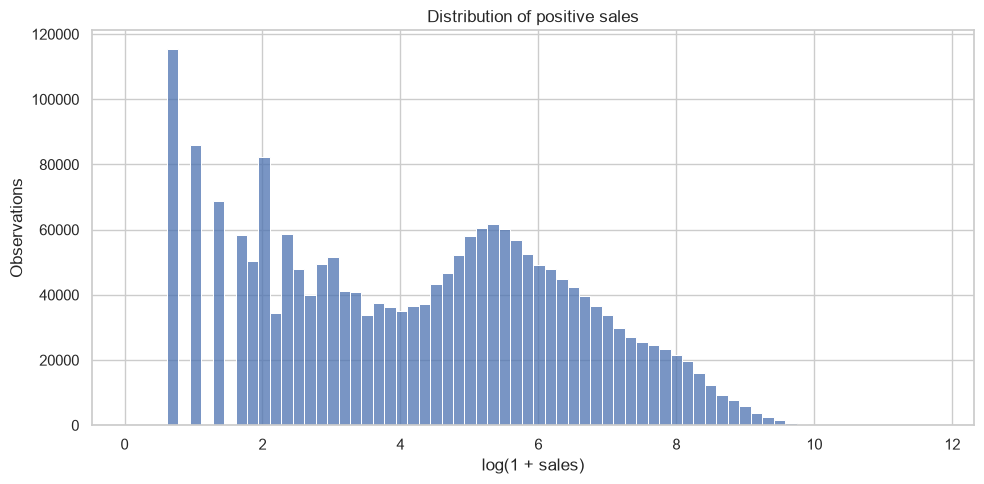

In [26]:
positive_log_sales = (
    datasets["train"]
    .filter(pl.col("sales") > 0)
    .select(
        pl.col("sales")
        .log1p()
        .alias("log_sales")
    )
    .collect()
    .get_column("log_sales")
    .to_numpy()
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    positive_log_sales,
    bins=70,
    ax=ax,
)

ax.set_title("Distribution of positive sales")
ax.set_xlabel("log(1 + sales)")
ax.set_ylabel("Observations")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "positive_sales_distribution.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [27]:
daily_sales = (
    datasets["train"]
    .group_by("date")
    .agg(
        pl.col("sales").sum().alias("total_sales"),
        pl.col("sales").mean().alias("mean_sales"),
        (pl.col("sales") == 0).mean().alias("zero_rate"),
    )
    .sort("date")
    .with_columns(
        pl.col("total_sales")
        .rolling_mean(window_size=30)
        .alias("rolling_mean_30d")
    )
    .collect()
)

daily_sales.head()

date,total_sales,mean_sales,zero_rate,rolling_mean_30d
date,f64,f64,f64,f64
2013-01-01,2511.618999,1.409438,0.99046,null
2013-01-02,496092.417944,278.390807,0.515152,null
2013-01-03,361461.231124,202.840197,0.522447,null
2013-01-04,354459.677093,198.911154,0.517957,null
2013-01-05,477350.121229,267.873244,0.507856,null


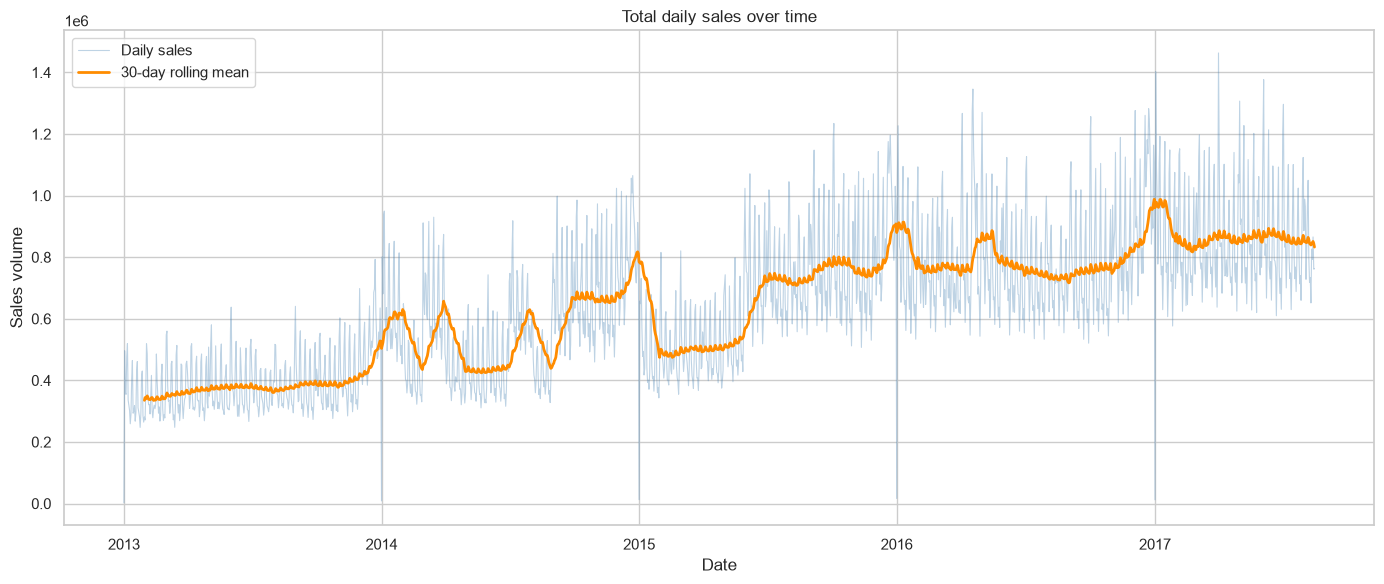

In [28]:
daily_sales_pd = daily_sales.to_pandas()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    daily_sales_pd["date"],
    daily_sales_pd["total_sales"],
    color="steelblue",
    alpha=0.35,
    linewidth=0.8,
    label="Daily sales",
)

ax.plot(
    daily_sales_pd["date"],
    daily_sales_pd["rolling_mean_30d"],
    color="darkorange",
    linewidth=2,
    label="30-day rolling mean",
)

ax.set_title("Total daily sales over time")
ax.set_xlabel("Date")
ax.set_ylabel("Sales volume")
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "daily_sales_trend.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

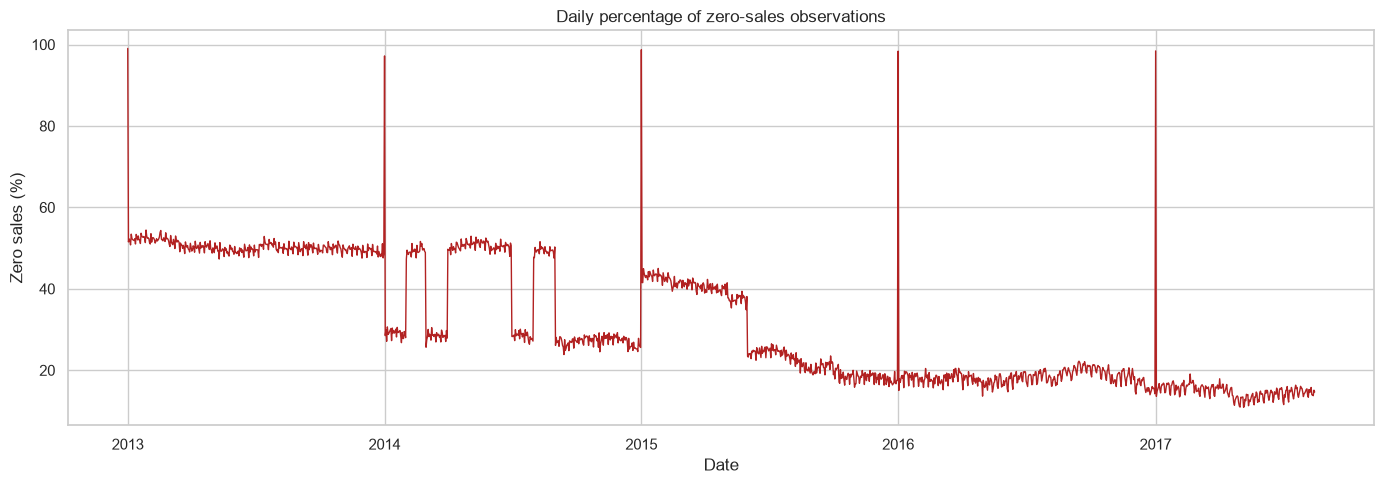

In [29]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    daily_sales_pd["date"],
    daily_sales_pd["zero_rate"] * 100,
    color="firebrick",
    linewidth=1,
)

ax.set_title("Daily percentage of zero-sales observations")
ax.set_xlabel("Date")
ax.set_ylabel("Zero sales (%)")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "daily_zero_sales_rate.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [30]:
weekday_order = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday",
}

weekday_sales = (
    daily_sales
    .with_columns(
        pl.col("date").dt.weekday().alias("weekday_number")
    )
    .group_by("weekday_number")
    .agg(
        pl.col("total_sales").mean().alias("mean_daily_sales"),
        pl.col("zero_rate").mean().alias("mean_zero_rate"),
    )
    .sort("weekday_number")
    .with_columns(
        pl.col("weekday_number")
        .replace_strict(weekday_order)
        .alias("weekday")
    )
)

weekday_sales

weekday_number,mean_daily_sales,mean_zero_rate,weekday
i8,f64,f64,str
1,617542.713052,0.310172,"""Monday"""
2,569926.087922,0.314676,"""Tuesday"""
3,593244.553472,0.315025,"""Wednesday"""
4,505269.201115,0.31705,"""Thursday"""
5,579574.361085,0.316353,"""Friday"""
6,772205.593943,0.297377,"""Saturday"""
7,825218.121579,0.320064,"""Sunday"""


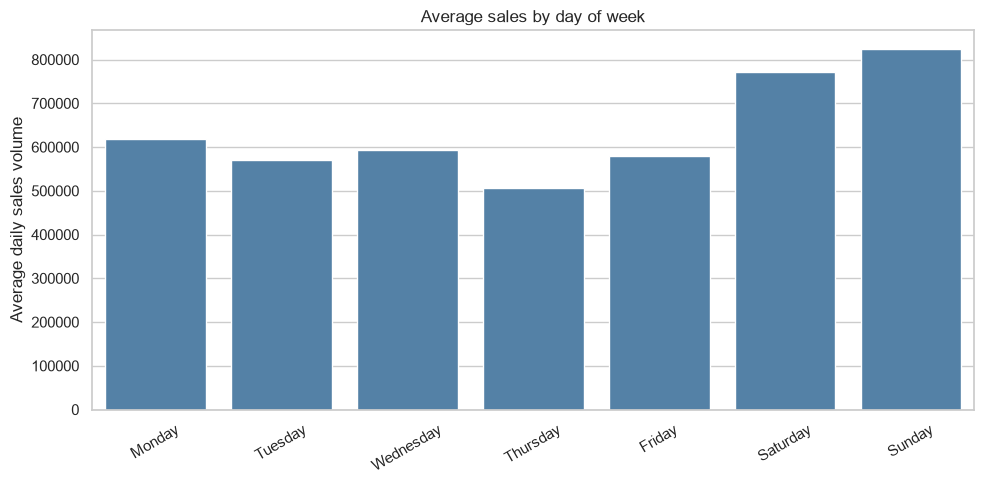

In [31]:
weekday_sales_pd = weekday_sales.to_pandas()

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=weekday_sales_pd,
    x="weekday",
    y="mean_daily_sales",
    color="steelblue",
    ax=ax,
)

ax.set_title("Average sales by day of week")
ax.set_xlabel("")
ax.set_ylabel("Average daily sales volume")
ax.tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "sales_by_weekday.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [32]:
family_summary = (
    datasets["train"]
    .group_by("family")
    .agg(
        pl.col("sales").sum().alias("total_sales"),
        pl.col("sales").mean().alias("mean_sales"),
        pl.col("sales").median().alias("median_sales"),
        (pl.col("sales") == 0).mean().alias("zero_rate"),
        pl.col("sales").max().alias("maximum_sales"),
    )
    .sort("total_sales", descending=True)
    .collect()
)

family_summary.head(15)

family,total_sales,mean_sales,median_sales,zero_rate,maximum_sales
str,f64,f64,f64,f64,f64
"""GROCERY I""",3.4346e8,3776.9721,3185.0,0.080628,124717.0
"""BEVERAGES""",2.16954486e8,2385.793151,1784.0,0.080617,25413.0
"""PRODUCE""",1.2270e8,1349.352123,398.2905,0.283551,17850.615
"""CLEANING""",9.7521289e7,1072.416744,938.0,0.080617,11377.0
"""DAIRY""",6.4487709e7,709.154889,520.0,0.080617,5636.0
…,…,…,…,…,…
"""HOME CARE""",1.6022744e7,176.198029,143.0,0.40909,2504.0
"""EGGS""",1.5588296e7,171.420516,131.0,0.080617,3110.0
"""FROZEN FOODS""",1.4074e7,154.766954,83.0,0.080914,14541.55


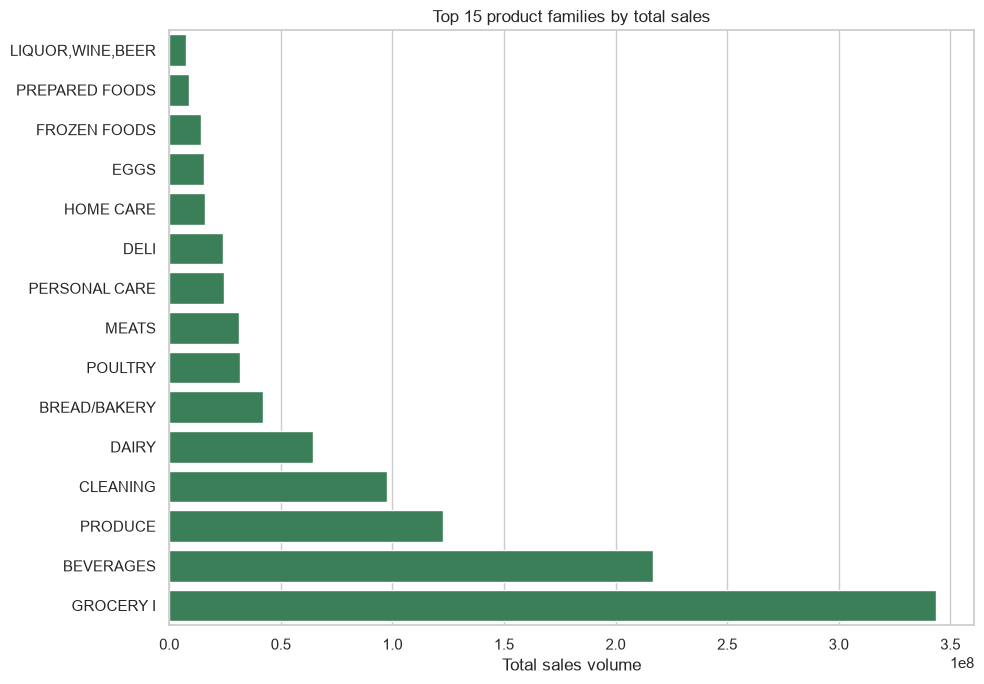

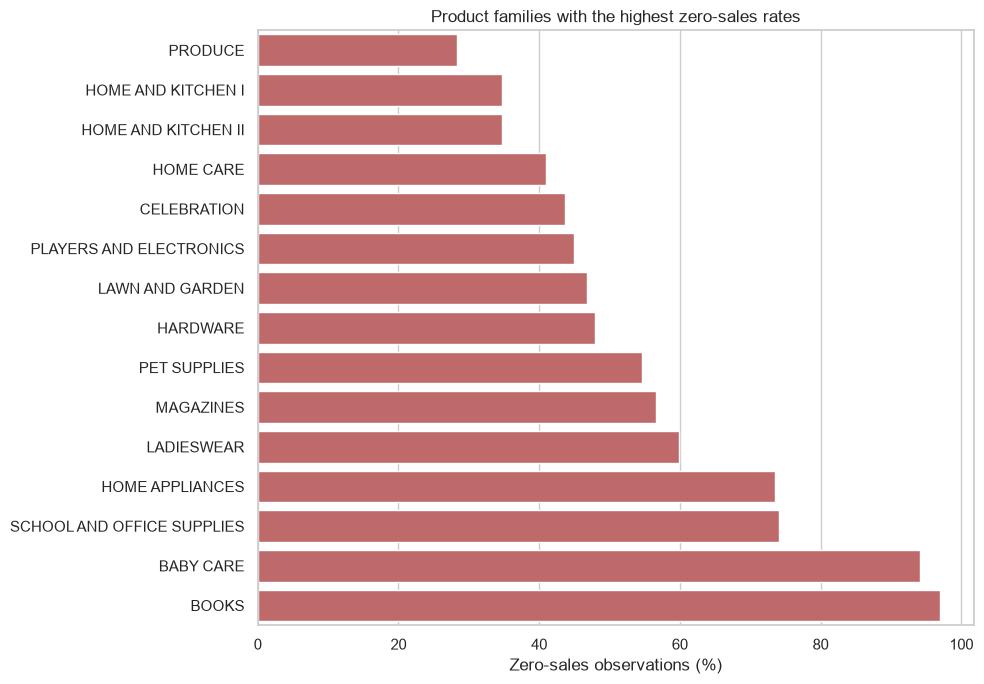

family,zero_rate,mean_sales,total_sales
str,f64,f64,f64
"""BOOKS""",0.96955,0.070797,6438.0
"""BABY CARE""",0.94131,0.110528,10051.0
"""SCHOOL AND OFFICE SUPPLIES""",0.740829,2.961599,269316.0
"""HOME APPLIANCES""",0.735176,0.457476,41601.0
"""LADIESWEAR""",0.598465,7.160629,651159.0
…,…,…,…
"""CELEBRATION""",0.43634,8.370469,761177.0
"""HOME CARE""",0.40909,176.198029,1.6022744e7
"""HOME AND KITCHEN II""",0.347134,16.72242,1.52067e6


In [33]:
top_families_pd = (
    family_summary
    .head(15)
    .sort("total_sales")
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=top_families_pd, x="total_sales", y="family", color="seagreen", ax=ax)
ax.set_title("Top 15 product families by total sales")
ax.set_xlabel("Total sales volume")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "top_families_by_sales.png", dpi=150, bbox_inches="tight")
plt.show()

high_zero_families = (
    family_summary
    .sort("zero_rate", descending=True)
    .select("family", "zero_rate", "mean_sales", "total_sales")
)

zero_families_pd = (
    high_zero_families
    .head(15)
    .sort("zero_rate")
    .with_columns((pl.col("zero_rate") * 100).alias("zero_percentage"))
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=zero_families_pd, x="zero_percentage", y="family", color="indianred", ax=ax)
ax.set_title("Product families with the highest zero-sales rates")
ax.set_xlabel("Zero-sales observations (%)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "families_zero_sales_rate.png", dpi=150, bbox_inches="tight")
plt.show()

high_zero_families.head(15)

In [34]:
store_summary = (
    datasets["train"]
    .group_by("store_nbr")
    .agg(
        pl.col("sales").sum().alias("total_sales"),
        pl.col("sales").mean().alias("mean_sales"),
        (pl.col("sales") == 0).mean().alias("zero_rate"),
    )
    .join(
        datasets["stores"],
        on="store_nbr",
        how="left",
    )
    .sort("total_sales", descending=True)
    .collect()
)

store_summary.head(15)

store_nbr,total_sales,mean_sales,zero_rate,city,state,type,cluster
i64,f64,f64,f64,str,str,str,i64
44,6.2088e7,1117.245254,0.179479,"""Quito""","""Pichincha""","""A""",5
45,5.4498e7,980.673908,0.193587,"""Quito""","""Pichincha""","""A""",11
47,5.0948e7,916.798209,0.189538,"""Quito""","""Pichincha""","""A""",14
3,5.0482e7,908.405495,0.181404,"""Quito""","""Pichincha""","""D""",8
49,4.3420e7,781.33045,0.193479,"""Quito""","""Pichincha""","""A""",11
…,…,…,…,…,…,…,…
11,2.8326e7,509.709179,0.241039,"""Cayambe""","""Pichincha""","""B""",6
7,2.6952e7,484.993334,0.208324,"""Quito""","""Pichincha""","""D""",8
9,2.6409e7,475.229271,0.219463,"""Quito""","""Pichincha""","""B""",6


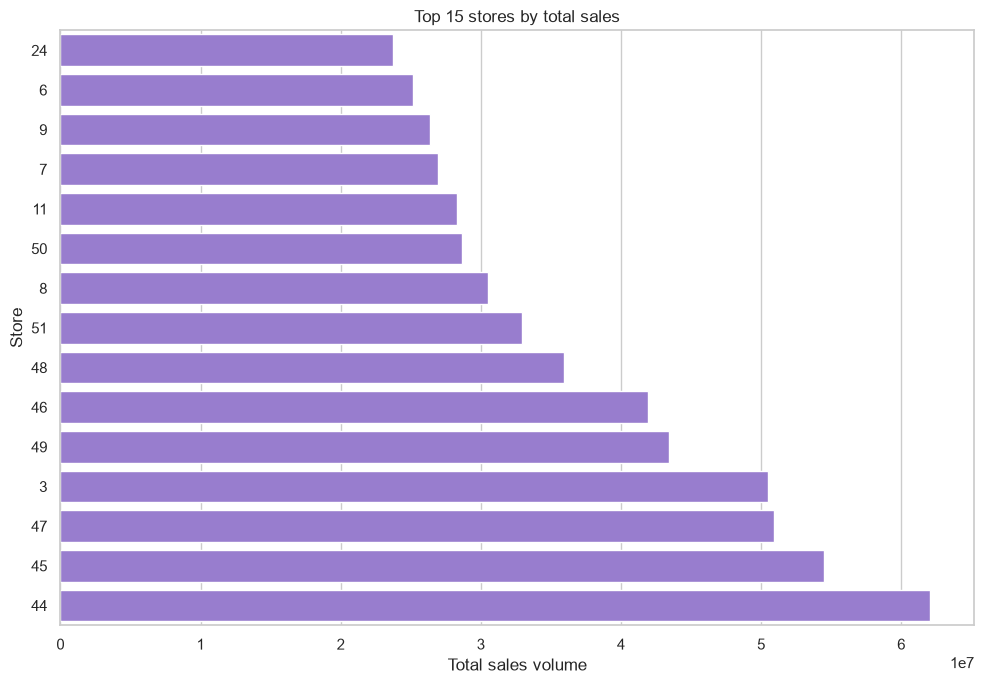

In [35]:
top_stores_pd = (
    store_summary
    .head(15)
    .sort("total_sales")
    .with_columns(
        pl.col("store_nbr").cast(pl.String)
    )
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    data=top_stores_pd,
    x="total_sales",
    y="store_nbr",
    color="mediumpurple",
    ax=ax,
)

ax.set_title("Top 15 stores by total sales")
ax.set_xlabel("Total sales volume")
ax.set_ylabel("Store")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "top_stores_by_sales.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [36]:
promotion_sales = (
    datasets["train"]
    .with_columns(
        (pl.col("onpromotion") > 0).alias("has_promotion")
    )
    .group_by("has_promotion")
    .agg(
        pl.len().alias("observations"),
        pl.col("sales").mean().alias("mean_sales"),
        pl.col("sales").median().alias("median_sales"),
        pl.col("sales").sum().alias("total_sales"),
        (pl.col("sales") == 0).mean().alias("zero_rate"),
    )
    .sort("has_promotion")
    .collect()
)

promotion_sales

has_promotion,observations,mean_sales,median_sales,total_sales,zero_rate
bool,u32,f64,f64,f64,f64
false,2389559,158.246681,3.0,3.7814e8,0.393007
true,611329,1137.69373,373.0,6.9551e8,0.000028


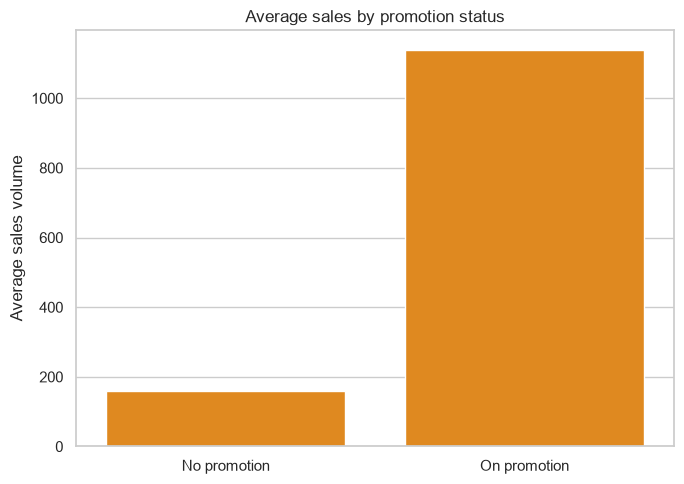

type,stores,total_sales,mean_sales_per_store,mean_zero_rate
str,u32,f64,f64,f64
"""A""",9,3.5304e8,3.9227e7,0.278406
"""D""",18,3.5108e8,1.9505e7,0.266766
"""C""",15,1.6443e8,1.0962e7,0.359604
"""B""",8,1.4526e8,1.8158e7,0.333005
"""E""",4,5.9822e7,1.4956e7,0.383448


In [37]:
store_type_summary = (
    store_summary
    .group_by("type")
    .agg(
        pl.len().alias("stores"),
        pl.col("total_sales").sum().alias("total_sales"),
        pl.col("total_sales").mean().alias("mean_sales_per_store"),
        pl.col("zero_rate").mean().alias("mean_zero_rate"),
    )
    .sort("total_sales", descending=True)
)

promotion_sales_pd = (
    promotion_sales
    .with_columns(
        pl.when(pl.col("has_promotion"))
        .then(pl.lit("On promotion"))
        .otherwise(pl.lit("No promotion"))
        .alias("promotion_status")
    )
    .to_pandas()
)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=promotion_sales_pd, x="promotion_status", y="mean_sales", color="darkorange", ax=ax)
ax.set_title("Average sales by promotion status")
ax.set_xlabel("")
ax.set_ylabel("Average sales volume")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sales_by_promotion_status.png", dpi=150, bbox_inches="tight")
plt.show()

store_type_summary

In [38]:
sales_p999 = (
    datasets["train"]
    .select(pl.col("sales").quantile(0.999).alias("p999"))
    .collect()
    .item()
)

extreme_sales = (
    datasets["train"]
    .filter(pl.col("sales") >= sales_p999)
    .sort("sales", descending=True)
    .head(20)
    .collect()
)

print(f"99.9th percentile threshold: {sales_p999:,.3f}")
extreme_sales

99.9th percentile threshold: 12,076.000


id,date,store_nbr,family,sales,onpromotion
i64,date,i64,str,f64,i64
2163723,2016-05-02,2,"""GROCERY I""",124717.0,59
2445984,2016-10-07,39,"""MEATS""",89576.36,0
2144154,2016-04-21,20,"""GROCERY I""",87438.516,53
2139699,2016-04-18,45,"""GROCERY I""",76090.0,38
2153031,2016-04-26,2,"""GROCERY I""",63434.0,30
…,…,…,…,…,…
1269390,2014-12-15,26,"""GROCERY I""",32209.0,17
1283844,2014-12-23,31,"""GROCERY I""",31851.158,3
2550582,2016-12-05,24,"""GROCERY I""",31689.0,98


In [39]:
print("SALES DISTRIBUTION")
print(sales_distribution)

print("\nWEEKDAY SUMMARY")
print(weekday_sales)

print("\nTOP FAMILIES")
print(family_summary.head(10))

print("\nHIGHEST ZERO-RATE FAMILIES")
print(high_zero_families.head(10))

print("\nTOP STORES")
print(store_summary.head(10))

print("\nSTORE TYPES")
print(store_type_summary)

print("\nPROMOTION COMPARISON")
print(promotion_sales)

print("\nEXTREME SALES")
print(extreme_sales)

SALES DISTRIBUTION
shape: (1, 12)
┌─────────────┬────────────┬────────┬─────────────┬───┬────────┬──────────┬────────────┬───────────┐
│ observation ┆ mean       ┆ median ┆ std         ┆ … ┆ p99    ┆ maximum  ┆ zero_sales ┆ zero_rate │
│ s           ┆ ---        ┆ ---    ┆ ---         ┆   ┆ ---    ┆ ---      ┆ ---        ┆ ---       │
│ ---         ┆ f64        ┆ f64    ┆ f64         ┆   ┆ f64    ┆ f64      ┆ u32        ┆ f64       │
│ u32         ┆            ┆        ┆             ┆   ┆        ┆          ┆            ┆           │
╞═════════════╪════════════╪════════╪═════════════╪═══╪════════╪══════════╪════════════╪═══════════╡
│ 3000888     ┆ 357.775749 ┆ 11.0   ┆ 1101.997721 ┆ … ┆ 5507.0 ┆ 124717.0 ┆ 939130     ┆ 0.312951  │
└─────────────┴────────────┴────────┴─────────────┴───┴────────┴──────────┴────────────┴───────────┘

WEEKDAY SUMMARY
shape: (7, 4)
┌────────────────┬──────────────────┬────────────────┬───────────┐
│ weekday_number ┆ mean_daily_sales ┆ mean_zero_rate ┆ weekd

## EDA findings

- Sales are strongly right-skewed: the mean is much larger than the median, and extreme observations require separate review rather than automatic removal.
- Zero sales represent approximately 31.3% of training observations, so zeros are a structural characteristic of the target rather than a rare anomaly.
- Average chain-wide sales are highest on weekends, especially Sunday and Saturday, indicating a strong weekly seasonal pattern.
- Grocery I and Beverages dominate total sales volume, while product families differ substantially in their zero-sales frequency.
- The leading stores are concentrated in Quito, but store type, city, cluster, and opening history must be considered before interpreting performance differences.
- Rows with promotional activity have substantially higher sales and almost no zero-sales observations. This is an association, not a causal estimate of promotion uplift.
- These findings support calendar features, store and family identifiers, promotion features, lagged sales, and rolling statistics for the forecasting stage.